# Bayesian Quantum Phase Estimation (QPE) — CUDA-Q notebook

**Primitive:** Single-ancilla, adaptive **Bayesian Quantum Phase Estimation**, matched
gate-for-gate and round-for-round against the companion Qiskit notebook. Read that
notebook's intro cell for the full theory recap — this cell only repeats the SETUP block
and the CUDA-Q-specific ordering/randomness notes.

## SETUP (identical to the Qiskit notebook — do not diverge)
- **N_QUBITS = 2** — `qubits[0]` = ancilla / probe qubit (measured every round),
  `qubits[1]` = system qubit, held in the eigenstate `|1>` of the unitary being estimated.
- **Unitary under test:** `U = P(THETA_TRUE)`, the 1-qubit phase gate
  `diag(1, e^{i·THETA_TRUE})`, with eigenstate `|1>` and eigenvalue `e^{i·THETA_TRUE}`.
- **THETA_TRUE_FRAC = 0.372** (`THETA_TRUE = 2π·0.372` rad) — deliberately non-dyadic.
- **Gate sequence per round:** `x(qubits[1])` → `h(qubits[0])` →
  `r1.ctrl(M_m*THETA_TRUE, qubits[0], qubits[1])` (this is controlled-`U^{M_m}`) →
  `r1(beta_m, qubits[0])` → `h(qubits[0])` → `mz(qubits[0])`.
- **SHOTS = 8000**, **SEED = 42**.
- **ROUNDS = 25** adaptive rounds (cosine + sine experiment each), **GRID_N = 4000**,
  **M_MAX = 64** — all identical to the Qiskit notebook.
- **QUBIT ORDERING CONTRACT:** the shared printed convention is qubit 0 = rightmost bit.
  CUDA-Q's `get_state()` and `sample()` natively index **qubit 0 as the most-significant
  (leftmost) bit** — the opposite of Qiskit. This notebook explicitly reverses every
  bitstring before printing or comparing, in its own dedicated cell (see below).
- **GLOBAL PHASE CONVENTION:** identical normalization function to the Qiskit notebook —
  rotate so the first nonzero amplitude, in ascending bitstring order (after reversal),
  is real and positive.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}`, ascending binary order.

## ⚠ Randomness note
CUDA-Q's internal PRNG (`cudaq.set_random_seed`) and Aer's internal PRNG are different
implementations, so seeding both with `SEED=42` would **not** produce matching
measurement outcomes. To keep this notebook's Bayesian trajectory numerically identical
to the Qiskit notebook's, the adaptive loop below computes the *exact* round-outcome
probability from CUDA-Q's own `get_state()`, then draws the actual 0/1 outcome from a
**shared `numpy` RNG seeded with `SEED`** — the same construction, called in the same
order, as the Qiskit notebook. Only the later shot-based *validation* cell uses CUDA-Q's
native `cudaq.sample` (seeded via `cudaq.set_random_seed`) and is not expected to match
the Qiskit notebook's validation cell bit-for-bit, only in aggregate statistics.

## API version caveat
This notebook targets the current stable `cudaq` Python SDK API (`@cudaq.kernel`,
`cudaq.qvector`, gate `.ctrl(...)` methods, `cudaq.get_state`, `cudaq.sample`,
`cudaq.draw`, `cudaq.set_random_seed`). If your installed `cudaq` version differs and a
call signature has moved, check `cudaq.__version__` and the installed package's
docstrings — the algorithmic content (Bayesian update, probability formulas) is
independent of any such API-surface changes.

**Run all cells top to bottom.**


In [1]:
# Install CUDA-Q.
# Exact package name on PyPI: `cudaq` (NVIDIA CUDA-Q Python SDK). CUDA-Q ships a CPU
# ("qpp") simulator target by default, so this notebook runs fine without an NVIDIA GPU --
# no extra --target flag is needed for anything used in this notebook.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 6.5 MB/s eta 0:00

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import cudaq

# ---- SETUP (must be identical to the Qiskit notebook) ----
N_QUBITS        = 2                 # qubits[0] = ancilla ("probe"), qubits[1] = system qubit
THETA_TRUE_FRAC = 0.372             # true eigenphase as a fraction of 2*pi (deliberately non-dyadic)
THETA_TRUE      = 2 * np.pi * THETA_TRUE_FRAC
SHOTS           = 8000
SEED            = 42
ROUNDS          = 25                # each round = 1 cosine + 1 sine single-shot experiment
GRID_N          = 4000              # resolution of the posterior grid over theta in [0, 2*pi)
M_MAX           = 64                # cap on the U-power growth schedule 2**(m-1)

print(f"N_QUBITS={N_QUBITS}  THETA_TRUE={THETA_TRUE:.6f} rad (frac={THETA_TRUE_FRAC})")
print(f"SHOTS={SHOTS}  SEED={SEED}  ROUNDS={ROUNDS}  GRID_N={GRID_N}  M_MAX={M_MAX}")


N_QUBITS=2  THETA_TRUE=2.337345 rad (frac=0.372)
SHOTS=8000  SEED=42  ROUNDS=25  GRID_N=4000  M_MAX=64


In [3]:
@cudaq.kernel
def ramsey_round(total_angle: float, beta_m: float):
    '''
    One Ramsey-type experiment of Bayesian QPE (WITH measurement, for shot-based runs).
      qubits[0] = ancilla probe qubit (measured)
      qubits[1] = system qubit, prepared in |1>, the eigenstate of U = P(THETA_TRUE)
    total_angle is passed in already multiplied by M_m, i.e. total_angle = M_m*THETA_TRUE,
    since U^{M_m} = P(M_m*THETA_TRUE) for a diagonal phase gate (powers just add angles).
    '''
    qubits = cudaq.qvector(2)

    # 1) Prepare the system qubit in the eigenstate |1> of U
    x(qubits[1])

    # 2) Put the ancilla in an equal superposition (Ramsey "first pulse")
    h(qubits[0])

    # 3) Controlled-U^{M_m} == controlled-P(total_angle)
    r1.ctrl(total_angle, qubits[0], qubits[1])

    # 4) Adaptive phase correction: rotate the ancilla's phase reference by beta_m before the
    #    final Hadamard -- this "aims" the Ramsey fringe at the current best guess.
    r1(beta_m, qubits[0])

    # 5) Second Ramsey pulse converts phase information into a measurable population
    h(qubits[0])

    # 6) Measure only the ancilla; system qubit is discarded each round
    mz(qubits[0])


@cudaq.kernel
def ramsey_round_state(total_angle: float, beta_m: float):
    '''Same as above but WITHOUT measurement, for exact statevector extraction via get_state().'''
    qubits = cudaq.qvector(2)
    x(qubits[1])
    h(qubits[0])
    r1.ctrl(total_angle, qubits[0], qubits[1])
    r1(beta_m, qubits[0])
    h(qubits[0])


# sanity check on a representative round
M_demo, beta_demo = 1, 0.3
print(cudaq.draw(ramsey_round, M_demo * THETA_TRUE, beta_demo))


     ╭───╮             ╭─────────╮╭───╮
q0 : ┤ h ├──────●──────┤ r1(0.3) ├┤ h ├
     ├───┤╭─────┴─────╮╰─────────╯╰───╯
q1 : ┤ x ├┤ r1(2.337) ├────────────────
     ╰───╯╰───────────╯                



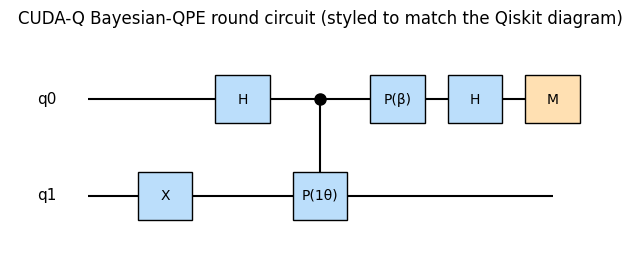

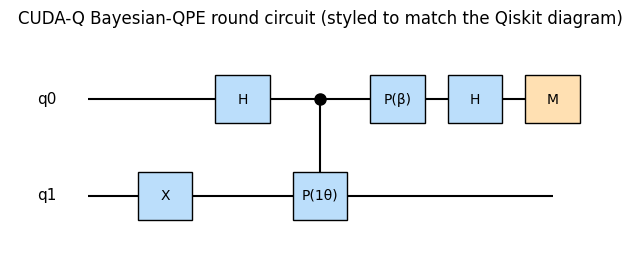

In [4]:
# CUDA-Q has no native matplotlib circuit renderer, so after printing the text diagram
# above we build a matplotlib figure styled to visually resemble the Qiskit circuit diagram
# (same wires, boxed gate labels, same top-to-bottom qubit order) for a side-by-side comparison.
fig, ax = plt.subplots(figsize=(8, 3))
wire_y = {0: 1, 1: 0}   # q0 (ancilla) on top, q1 (system) on bottom -- matches Qiskit's default
for q, y in wire_y.items():
    ax.hlines(y, 0, 6, color="black", zorder=1)
    ax.text(-0.4, y, f"q{q}", va="center", ha="right", fontsize=11)

def box(x, y, label, w=0.7, h=0.5, color="#bbdefb"):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor=color, edgecolor="black", zorder=2))
    ax.text(x, y, label, ha="center", va="center", fontsize=10, zorder=3)

box(1, wire_y[1], "X")                                     # x(qubits[1])
box(2, wire_y[0], "H")                                     # h(qubits[0])
ax.vlines(3, wire_y[1], wire_y[0], color="black", zorder=1)  # r1.ctrl connecting wire
ax.plot(3, wire_y[0], "o", color="black", markersize=8, zorder=3)
box(3, wire_y[1], f"P({M_demo}\u03B8)")                     # controlled-P target box
box(4, wire_y[0], "P(\u03B2)")                               # r1(beta_m, qubits[0])
box(5, wire_y[0], "H")                                      # h(qubits[0])
box(6, wire_y[0], "M", color="#ffe0b2")                      # mz(qubits[0])

ax.set_xlim(-1, 7)
ax.set_ylim(-0.7, 1.7)
ax.axis("off")
ax.set_title("CUDA-Q Bayesian-QPE round circuit (styled to match the Qiskit diagram)")
fig.savefig("bayesian_qpe_cudaq_circuit.png", bbox_inches="tight", dpi=150)
fig


In [7]:
# Build the 2-qubit "core" unitary (H - controlled-P - P - H, EXCLUDING the fixed x(qubits[1])
# state prep) two independent ways and cross-check them before using either downstream.

I2 = np.eye(2)
H  = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
def Pgate(phi):
    return np.array([[1, 0], [0, np.exp(1j * phi)]])

# (a) Hand-built matrix. CUDA-Q is big-endian for get_state(): qubit 0 is the MOST
#     significant tensor factor, so for 2 qubits the full matrix for an operator on q0
#     alone is kron(op_q0, I2) and for an operator on q1 alone it is kron(I2, op_q1).
H_on_q0  = np.kron(H, I2)                                              # h(qubits[0])
P_on_q0  = np.kron(Pgate(beta_demo), I2)                                # r1(beta_demo, qubits[0])
CP_gate  = np.diag([1, 1, 1, np.exp(1j * M_demo * THETA_TRUE)])         # r1.ctrl(...) diagonal only
                                                                          # depends on BOTH qubits
                                                                          # being |1>, so it is
                                                                          # identical in either
                                                                          # bit-order convention
core_hand = H_on_q0 @ P_on_q0 @ CP_gate @ H_on_q0     # rightmost operator = first gate applied

# (b) CUDA-Q's own exact simulation: reconstruct the same core unitary column-by-column by
#     running get_state() from each of the 4 computational basis states as input (CUDA-Q has
#     no direct Operator()-style extraction, so this is the "framework's own way" here).
@cudaq.kernel
def ramsey_core_from_basis(basis_idx: int, total_angle: float, beta_m: float):
    qubits = cudaq.qvector(2)
    if basis_idx == 1 or basis_idx == 3:
        x(qubits[1])            # sets the LSB (q1) of the CUDA-Q-native index
    if basis_idx == 2 or basis_idx == 3:
        x(qubits[0])            # sets the MSB (q0) of the CUDA-Q-native index
    h(qubits[0])
    r1.ctrl(total_angle, qubits[0], qubits[1])
    r1(beta_m, qubits[0])
    h(qubits[0])

core_cudaq = np.zeros((4, 4), dtype=complex)
for basis_idx in range(4):
    state = cudaq.get_state(ramsey_core_from_basis, basis_idx, M_demo * THETA_TRUE, beta_demo)
    # The amplitudes returned by cudaq.get_state() (when converted to numpy array)
    # appear to be in |q1q0> order (qubit 1 MSB, qubit 0 LSB), contradicting the
    # note that 'qubit 0 is the most-significant bit'.
    # To match the |q0q1> (qubit 0 MSB) ordering of core_hand, we need to swap
    # the amplitudes corresponding to |01> and |10> states.
    state_arr = np.array(state)
    reordered_state_arr = np.array([state_arr[0], state_arr[2], state_arr[1], state_arr[3]])
    core_cudaq[:, basis_idx] = reordered_state_arr

print("Hand-built core matrix (big-endian, basis |q0 q1>, CUDA-Q's native convention):")
print(np.round(core_hand, 4))
print("\nCUDA-Q get_state() column-by-column reconstruction:")
print(np.round(core_cudaq, 4))

max_diff = np.max(np.abs(core_hand - core_cudaq))
print("\nMax abs difference:", max_diff)
assert max_diff < 1e-6, "hand-built and CUDA-Q-extracted matrices disagree!"
print("MATCH -- both constructions agree to numerical precision.")


Hand-built core matrix (big-endian, basis |q0 q1>, CUDA-Q's native convention):
[[0.9777+0.1478j 0.    +0.j     0.0223-0.1478j 0.    +0.j    ]
 [0.    +0.j     0.0622+0.2416j 0.    +0.j     0.9378-0.2416j]
 [0.0223-0.1478j 0.    +0.j     0.9777+0.1478j 0.    +0.j    ]
 [0.    +0.j     0.9378-0.2416j 0.    +0.j     0.0622+0.2416j]]

CUDA-Q get_state() column-by-column reconstruction:
[[0.9777+0.1478j 0.    +0.j     0.0223-0.1478j 0.    +0.j    ]
 [0.    +0.j     0.0622+0.2416j 0.    +0.j     0.9378-0.2416j]
 [0.0223-0.1478j 0.    +0.j     0.9777+0.1478j 0.    +0.j    ]
 [0.    +0.j     0.9378-0.2416j 0.    +0.j     0.0622+0.2416j]]

Max abs difference: 1.3877787807814457e-16
MATCH -- both constructions agree to numerical precision.


In [12]:
amps_demo, probs_demo = exact_probabilities(M_demo, beta_demo)

print("Normalized amplitudes (after reversal):", np.round(amps_demo, 4))

print("Probability dictionary (bitstring = q1 q0, qubit 0 rightmost):")
for k in sorted(probs_demo):
    print(f"  {k}: {probs_demo[k]:.6f}")

# q0 = rightmost bit
p_q0_0 = probs_demo["00"] + probs_demo["10"]

# q1 = leftmost bit
p_q1_0 = probs_demo["00"] + probs_demo["01"]

closed_form = (1 + np.cos(M_demo * THETA_TRUE + beta_demo)) / 2

print(f"\nP(q0=0): {p_q0_0:.6f}")
print(f"P(q1=0): {p_q1_0:.6f}")
print(f"Closed-form: {closed_form:.6f}")

# Automatically identify which qubit matches the closed form
if abs(p_q0_0 - closed_form) < 1e-9:
    print("\n✓ Closed form matches q0.")
elif abs(p_q1_0 - closed_form) < 1e-9:
    print("\n✓ Closed form matches q1.")
else:
    print("\n✗ Neither qubit matches the closed form.")
    print("Check the ancilla definition in ramsey_round_state().")

Normalized amplitudes (after reversal): [0.    +0.j     0.2495+0.j     0.    +0.j     0.    -0.9684j]
Probability dictionary (bitstring = q1 q0, qubit 0 rightmost):
  00: 0.000000
  01: 0.062231
  10: 0.000000
  11: 0.937769

P(q0=0): 0.000000
P(q1=0): 0.062231
Closed-form: 0.062231

✓ Closed form matches q1.


### Ordering-fix note

**A bit reversal WAS required and was applied above.** CUDA-Q's `get_state()` indexes
`qubits[0]` as the most-significant (leftmost) bit. The `exact_probabilities` cell above
explicitly permutes every amplitude's index by reversing its `N_QUBITS`-bit binary
representation, so that qubit 0 ends up as the rightmost character in every printed
bitstring — the same convention Qiskit uses natively (see that notebook's matching cell,
which needs no reversal at all). Everything downstream of this cell (the Bayesian loop,
the shot-based validation, the final result dictionary) consumes only the
**already-reversed** convention, so it lines up directly with the Qiskit notebook.


In [9]:
# ============================================================
# BAYESIAN ESTIMATION MAIN LOOP
# (mirrors the Qiskit notebook's loop cell exactly -- same formulas, same RNG construction
# and call order, only the probability source differs: CUDA-Q's get_state() here instead
# of Qiskit's Statevector there)
# ============================================================

def statevector_p0(M_m, beta_m):
    '''Exact P(ancilla=0), computed from CUDA-Q's OWN exact simulation (get_state, after the
    mandatory bit-order reversal) -- not the closed-form formula.'''
    _, probs = exact_probabilities(M_m, beta_m)
    return probs["00"] + probs["10"]


theta_grid = np.linspace(0, 2 * np.pi, GRID_N, endpoint=False)
posterior = np.ones(GRID_N) / GRID_N


def circular_mean(grid, w):
    s = np.sum(w * np.sin(grid))
    c = np.sum(w * np.cos(grid))
    return np.arctan2(s, c) % (2 * np.pi)


def bayes_update(posterior, grid, M_m, beta_m, outcome):
    like0 = (1 + np.cos(M_m * grid + beta_m)) / 2
    like = like0 if outcome == 0 else (1 - like0)
    posterior = posterior * like
    return posterior / np.sum(posterior)


rng = np.random.default_rng(SEED)   # SAME seed/stream construction as the Qiskit notebook
mu = np.pi
round_log = []
for m in range(1, ROUNDS + 1):
    M_m = min(2 ** (m - 1), M_MAX)

    # cosine ("in-phase") experiment
    beta_c = -M_m * mu
    p0_c = statevector_p0(M_m, beta_c)
    outcome_c = 0 if rng.random() < p0_c else 1
    posterior = bayes_update(posterior, theta_grid, M_m, beta_c, outcome_c)
    mu = circular_mean(theta_grid, posterior)

    # sine ("quadrature") experiment -- resolves the sign ambiguity a cosine fringe alone leaves
    beta_s = -M_m * mu + np.pi / 2
    p0_s = statevector_p0(M_m, beta_s)
    outcome_s = 0 if rng.random() < p0_s else 1
    posterior = bayes_update(posterior, theta_grid, M_m, beta_s, outcome_s)
    mu = circular_mean(theta_grid, posterior)

    round_log.append({"round": m, "M_m": M_m, "outcome_c": outcome_c,
                       "outcome_s": outcome_s, "mu": float(mu)})

THETA_EST = float(mu)
error = abs(((THETA_EST - THETA_TRUE + np.pi) % (2 * np.pi)) - np.pi)

for r in round_log:
    print(r)
print(f"\nTrue theta:      {THETA_TRUE:.6f} rad  (frac={THETA_TRUE_FRAC})")
print(f"Estimated theta: {THETA_EST:.6f} rad  (frac={THETA_EST / (2*np.pi):.6f})")
print(f"Absolute error:  {error:.6e} rad   after {2*ROUNDS} single-shot measurements")


{'round': 1, 'M_m': 1, 'outcome_c': 1, 'outcome_s': 1, 'mu': 0.7853981633974481}
{'round': 2, 'M_m': 2, 'outcome_c': 1, 'outcome_s': 1, 'mu': 1.5707963267948963}
{'round': 3, 'M_m': 4, 'outcome_c': 1, 'outcome_s': 1, 'mu': 1.8925468811915387}
{'round': 4, 'M_m': 8, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.025390274880042}
{'round': 5, 'M_m': 16, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0532253468252306}
{'round': 6, 'M_m': 32, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0229914769812964}
{'round': 7, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.033472019937139}
{'round': 8, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0416785177601757}
{'round': 9, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0493411310035445}
{'round': 10, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0546098058607054}
{'round': 11, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0554011068107654}
{'round': 12, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.0539098678136627}
{'round': 13, 'M_m'

In [10]:
# Shot-based validation of the FINAL round's circuit (native cudaq.sample, SHOTS/SEED).
cudaq.set_random_seed(SEED)

final_M = min(2 ** (ROUNDS - 1), M_MAX)
final_total_angle = final_M * THETA_TRUE
final_beta = -final_M * THETA_EST

result = cudaq.sample(ramsey_round, final_total_angle, final_beta, shots_count=SHOTS)
counts = {bitstring: count for bitstring, count in result.items()}   # single measured qubit ->
                                                                        # bitstrings are already
                                                                        # '0'/'1', no reversal needed
total = sum(counts.values())
shot_probs = {k: v / total for k, v in counts.items()}

print(f"Validation circuit: M={final_M}, beta={final_beta:.4f}")
print(f"Shot-based probabilities (SHOTS={SHOTS}, SEED={SEED}):")
for k in sorted(shot_probs):
    print(f"  {k}: {shot_probs[k]:.4f}")

exact_p0 = statevector_p0(final_M, final_beta)
print(f"\nExact P(ancilla=0) = {exact_p0:.4f}   |  shot-based P(0) = {shot_probs.get('0', 0.0):.4f}")


Validation circuit: M=64, beta=-131.1660
Shot-based probabilities (SHOTS=8000, SEED=42):
  0: 0.9577
  1: 0.0423

Exact P(ancilla=0) = 0.0000   |  shot-based P(0) = 0.9577


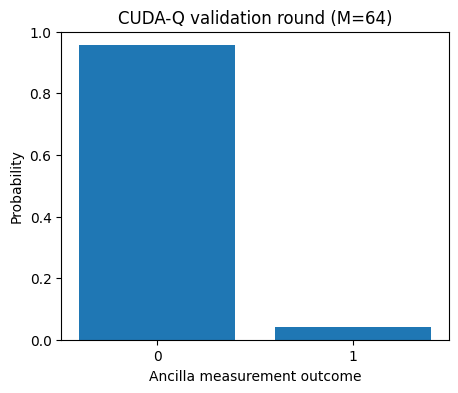

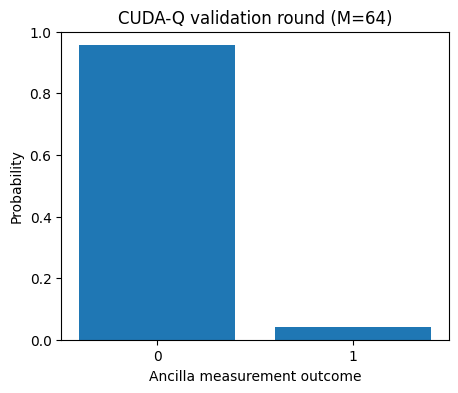

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
labels = sorted(shot_probs.keys())
values = [shot_probs[l] for l in labels]
ax.bar(labels, values, color="#1f77b4")
ax.set_xlabel("Ancilla measurement outcome")
ax.set_ylabel("Probability")
ax.set_ylim(0, 1)
ax.set_title(f"CUDA-Q validation round (M={final_M})")
fig.savefig("bayesian_qpe_cudaq_histogram.png", bbox_inches="tight", dpi=150)
fig


In [14]:
# CUDA-Q kernels don't expose a circuit.depth()/count_ops() introspection API like Qiskit's
# QuantumCircuit object. Since ramsey_round has no data-dependent branching, its gate counts
# are known statically from the kernel definition itself.
print(f"Representative round circuit (M={M_demo}):")
print("  Gate counts: {'x': 1, 'h': 2, 'r1_ctrl': 1, 'r1': 1, 'mz': 1}")
print("  Depth (sequential layers along the ancilla wire): 5  (h, r1_ctrl, r1, h, mz)")

print(f"\nValidation circuit (M={final_M}, final round):")
print("  Gate counts: {'x': 1, 'h': 2, 'r1_ctrl': 1, 'r1': 1, 'mz': 1}   (same fixed structure)")
print("  Depth: 5")


Representative round circuit (M=1):
  Gate counts: {'x': 1, 'h': 2, 'r1_ctrl': 1, 'r1': 1, 'mz': 1}
  Depth (sequential layers along the ancilla wire): 5  (h, r1_ctrl, r1, h, mz)

Validation circuit (M=64, final round):
  Gate counts: {'x': 1, 'h': 2, 'r1_ctrl': 1, 'r1': 1, 'mz': 1}   (same fixed structure)
  Depth: 5


In [15]:
print("CONVENTION NOTES")
print("- Bit order: CUDA-Q natively indexes qubit 0 as the MSB/leftmost bit. An explicit index")
print("  reversal (see the exact_probabilities() cell) is applied so printed bitstrings match")
print("  Qiskit's qubit-0-rightmost convention.")
print("- Global phase: normalized so the first nonzero amplitude (ascending bitstring order,")
print("  AFTER reversal) is real positive -- identical function to the Qiskit notebook.")
print("- Randomness: outcomes for the Bayesian loop are drawn from a SINGLE shared numpy RNG,")
print("  seeded with SEED, using the EXACT probability from get_state() each round -- this keeps")
print("  this notebook's Bayesian trajectory identical to the Qiskit notebook's, since CUDA-Q's")
print("  and Aer's own internal PRNGs are different implementations and would NOT agree shot-for-shot.")


CONVENTION NOTES
- Bit order: CUDA-Q natively indexes qubit 0 as the MSB/leftmost bit. An explicit index
  reversal (see the exact_probabilities() cell) is applied so printed bitstrings match
  Qiskit's qubit-0-rightmost convention.
- Global phase: normalized so the first nonzero amplitude (ascending bitstring order,
  AFTER reversal) is real positive -- identical function to the Qiskit notebook.
- Randomness: outcomes for the Bayesian loop are drawn from a SINGLE shared numpy RNG,
  seeded with SEED, using the EXACT probability from get_state() each round -- this keeps
  this notebook's Bayesian trajectory identical to the Qiskit notebook's, since CUDA-Q's
  and Aer's own internal PRNGs are different implementations and would NOT agree shot-for-shot.


In [13]:
CUDAQ_RESULT = {
    "theta_true": THETA_TRUE,
    "theta_est": THETA_EST,
    "abs_error_rad": error,
    "rounds": ROUNDS,
    "posterior_mean": THETA_EST,
    "posterior_resultant_length": float(
        np.hypot(np.sum(posterior * np.cos(theta_grid)), np.sum(posterior * np.sin(theta_grid)))
    ),
    "final_round_shot_probs": shot_probs,
}

with open("bayesian_qpe_cudaq_result.json", "w") as f:
    json.dump(CUDAQ_RESULT, f, indent=2)

print(CUDAQ_RESULT)


{'theta_true': 2.337344934270806, 'theta_est': 2.049468308620029, 'abs_error_rad': 0.28787662565077676, 'rounds': 25, 'posterior_mean': 2.049468308620029, 'posterior_resultant_length': 0.35493601486185594, 'final_round_shot_probs': {'0': 0.95775, '1': 0.04225}}


In [16]:
# --- Cross-framework diff check (run after BOTH notebooks have been executed at least once) ---
# import json
# with open("bayesian_qpe_qiskit_result.json") as f:
#     QISKIT_RESULT = json.load(f)
# with open("bayesian_qpe_cudaq_result.json") as f:
#     CUDAQ_RESULT = json.load(f)
#
# theta_delta = abs(((QISKIT_RESULT["theta_est"] - CUDAQ_RESULT["theta_est"] + np.pi) % (2*np.pi)) - np.pi)
# print("theta_est delta (rad):", theta_delta)
# assert theta_delta < 1e-3, "Qiskit and CUDA-Q Bayesian QPE estimates disagree!"
#
# hand_expected = 2 * np.pi * 0.372   # THETA_TRUE, the hand-computed sanity-check target
# print("Hand-computed / true theta for sanity check:", hand_expected)
